In [1]:

# Import the libraries needed for our payment analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

print("All libraries imported successfully!")


All libraries imported successfully!



# Payment Transaction Analytics Project

## Objective
Analyze 1,000 simulated payment transactions
to identify payment success rates, failures,
and transaction trends.

## Tools
- Python
- Pandas
- NumPy
- SQL
- Matplotlib

## Business Questions
1. How many transactions succeeded or failed?
2. What is the overall payment success rate?
3. Which payment method has the highest failure rate?
4. How does successful payment volume change over time?


In [2]:

# Step 3: Generate 1,000 fictional payment transactions

# Set up a random number generator
rng = np.random.default_rng(42)

# Create the payment dataset
transactions = pd.DataFrame({
    "transaction_id": range(1, 1001),

    "date": pd.date_range(
        start="2026-01-01",
        periods=1000,
        freq="6h"
    ),

    "amount": rng.uniform(10, 500, 1000).round(2),

    "payment_method": rng.choice(
        ["Card", "Bank Transfer", "Digital Wallet"],
        size=1000
    ),

    "status": rng.choice(
        ["Success", "Failed"],
        size=1000,
        p=[0.85, 0.15]
    )
})

# Show the first five transactions
transactions.head()


,transaction_id,date,amount,payment_method,status
0,1,2026-01-01 00:00:00,389.24,Digital Wallet,Success
1,2,2026-01-01 06:00:00,225.05,Card,Failed
2,3,2026-01-01 12:00:00,430.71,Bank Transfer,Success
3,4,2026-01-01 18:00:00,351.71,Bank Transfer,Success
4,5,2026-01-02 00:00:00,56.15,Digital Wallet,Success


In [3]:

# Step 4: Explore and understand the dataset

# Check the number of rows and columns
print("Dataset Shape:", transactions.shape)

# Display information about the dataset
print("\nDataset Information:")
transactions.info()

# Check for missing values
print("\nMissing Values:")
print(transactions.isnull().sum())


Dataset Shape: (1000, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   transaction_id  1000 non-null   int64         
 1   date            1000 non-null   datetime64[ns]
 2   amount          1000 non-null   float64       
 3   payment_method  1000 non-null   object        
 4   status          1000 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 39.2+ KB

Missing Values:
transaction_id    0
date              0
amount            0
payment_method    0
status            0
dtype: int64


In [4]:

# Step 5: Calculate payment success and failure rates

# Count the number of successful and failed payments
payment_counts = transactions["status"].value_counts()

print("Payment Status Counts:")
print(payment_counts)

# Calculate total transactions
total_transactions = len(transactions)

# Count successful transactions
successful_payments = (
    transactions["status"] == "Success"
).sum()

# Count failed transactions
failed_payments = (
    transactions["status"] == "Failed"
).sum()

# Calculate percentages
success_rate = (
    successful_payments / total_transactions
) * 100

failure_rate = (
    failed_payments / total_transactions
) * 100

# Display results
print("\nPayment Performance Summary:")
print("Total Transactions:", total_transactions)
print("Successful Payments:", successful_payments)
print("Failed Payments:", failed_payments)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Failure Rate: {failure_rate:.2f}%")


Payment Status Counts:
status
Success    849
Failed     151
Name: count, dtype: int64

Payment Performance Summary:
Total Transactions: 1000
Successful Payments: 849
Failed Payments: 151
Success Rate: 84.90%
Failure Rate: 15.10%


In [5]:

# Step 6: Create a SQL database

# Connect to a SQLite database
connection = sqlite3.connect("payments.db")

# Save the payment dataset into a SQL table
transactions.to_sql(
    "payments",
    connection,
    if_exists="replace",
    index=False
)

print("Payment database created successfully!")



Payment database created successfully!


In [6]:

# Step 6B: Count transactions using SQL

query = """
SELECT
    status,
    COUNT(*) AS total_transactions
FROM payments
GROUP BY status;
"""

# Execute the SQL query
sql_results = pd.read_sql_query(
    query,
    connection
)

# Display the results
print(sql_results)


    status  total_transactions
0   Failed                 151
1  Success                 849


In [7]:

# Step 7: Analyze payment failure rates by payment method

# Write the SQL query
query = """
SELECT
    payment_method,
    COUNT(*) AS total_transactions,

    SUM(
        CASE
            WHEN status = 'Failed' THEN 1
            ELSE 0
        END
    ) AS failed_transactions,

    ROUND(
        100.0 * SUM(
            CASE
                WHEN status = 'Failed' THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS failure_rate

FROM payments

GROUP BY payment_method

ORDER BY failure_rate DESC;
"""

# Execute the SQL query
payment_method_results = pd.read_sql_query(
    query,
    connection
)

# Display the results
print(payment_method_results)


   payment_method  total_transactions  failed_transactions  failure_rate
0  Digital Wallet                 330                   59         17.88
1   Bank Transfer                 340                   52         15.29
2            Card                 330                   40         12.12


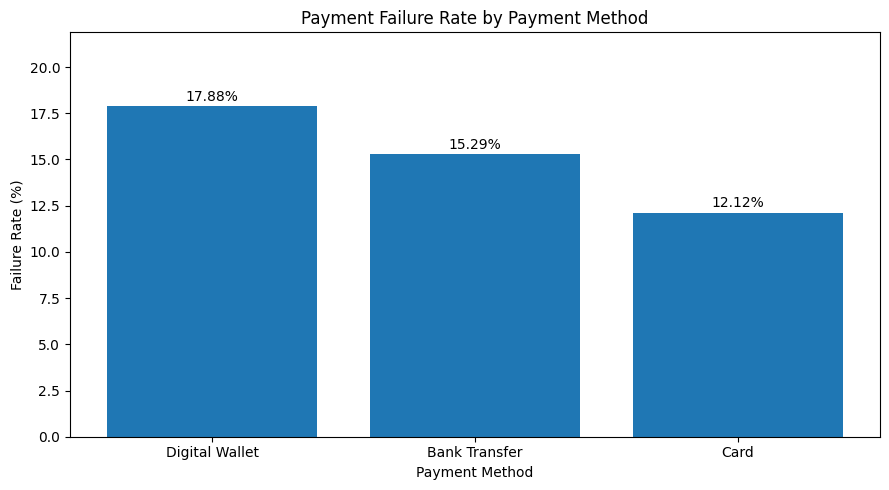

In [8]:

# Step 8A: Visualize failure rates by payment method

# Create a bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    payment_method_results["payment_method"],
    payment_method_results["failure_rate"]
)

# Add a title and labels
plt.title("Payment Failure Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Failure Rate (%)")

# Add percentage labels above each bar
for i, rate in enumerate(payment_method_results["failure_rate"]):
    plt.text(i, rate + 0.3, f"{rate:.2f}%", ha="center")

plt.ylim(0, payment_method_results["failure_rate"].max() + 4)

# Display chart
plt.tight_layout()
plt.show()


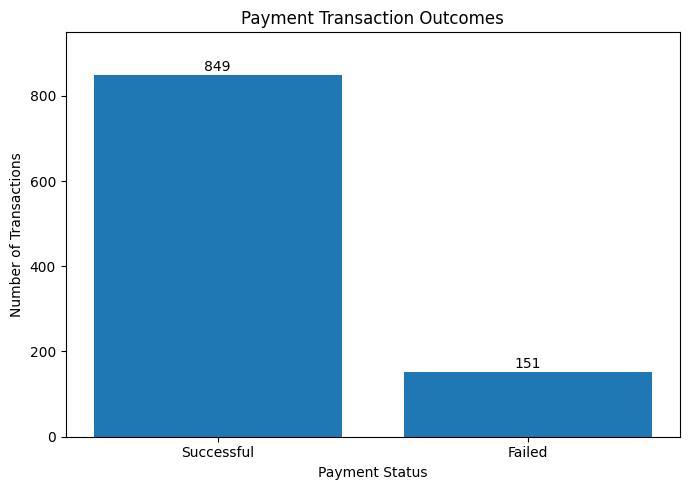

In [9]:

# Step 8C: Visualize successful and failed transactions

plt.figure(figsize=(7, 5))

# Create bar chart from Python results
plt.bar(
    ["Successful", "Failed"],
    [successful_payments, failed_payments]
)

# Add title and labels
plt.title("Payment Transaction Outcomes")
plt.xlabel("Payment Status")
plt.ylabel("Number of Transactions")

# Show counts above the bars
for i, count in enumerate([successful_payments, failed_payments]):
    plt.text(i, count + 10, str(count), ha="center")

plt.ylim(0, max(successful_payments, failed_payments) + 100)

plt.tight_layout()
plt.show()


In [10]:

# Step 9: Analyze monthly successful payment volume

# Select only successful transactions
successful_transactions = transactions[
    transactions["status"] == "Success"
].copy()

# Extract the month from each transaction date
successful_transactions["month"] = (
    successful_transactions["date"].dt.to_period("M")
)

# Calculate monthly successful payment volume
monthly_volume = successful_transactions.groupby(
    "month"
)["amount"].sum()

# Display the monthly results
print("Monthly Successful Payment Volume:")
print(monthly_volume)


Monthly Successful Payment Volume:
month
2026-01    26922.09
2026-02    22886.34
2026-03    27232.00
2026-04    26822.49
2026-05    26467.02
2026-06    27936.61
2026-07    24019.62
2026-08    28568.61
2026-09     6551.22
Freq: M, Name: amount, dtype: float64


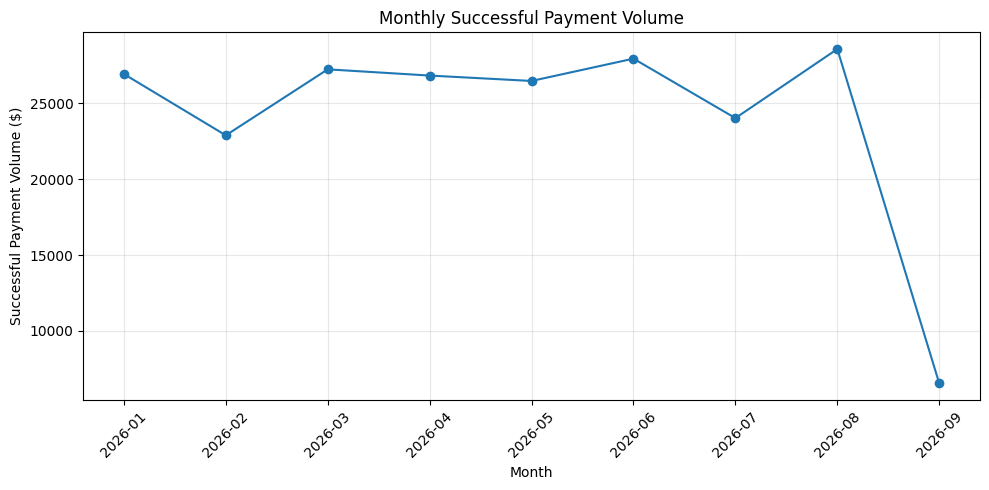

In [11]:

# Step 9B: Visualize monthly successful payment volume

# Create a line chart
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_volume.index.astype(str),
    monthly_volume.values,
    marker="o"
)

# Add chart title and labels
plt.title("Monthly Successful Payment Volume")
plt.xlabel("Month")
plt.ylabel("Successful Payment Volume ($)")

# Improve readability
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

# Display the chart
plt.tight_layout()
plt.show()


### Monthly Payment Analysis

**Objective:** Analyze monthly successful payment volume using Python and Pandas.

**Method:** Filtered successful transactions, grouped transactions by month, and calculated the total successful payment amount for each period.

**Findings:** **Findings:** August 2026 recorded the highest successful payment volume among the complete months analyzed, totaling $28,568.61. This finding was identified by filtering successful transactions and grouping payment amounts by month using Python and Pandas. The dataset is synthetic and does not represent actual business transactions.

**Business interpretation:** Changes in successful payment volume could reflect differences in transaction counts, payment amounts, or payment success rates. Additional analysis would be needed to identify the underlying reasons.

**Limitations:** This analysis uses randomly generated transaction data. The final month is incomplete, so its volume should not be directly compared with full months.

In [12]:

# Find the month with the highest payment volume
# Exclude September because it is incomplete

complete_months = monthly_volume[
    monthly_volume.index < pd.Period("2026-09", freq="M")
]

# Find the month with the highest payment volume
highest_month = complete_months.idxmax()

# Find the total payment volume for that month
highest_amount = complete_months.max()

# Display results
print("Highest Payment Month:", highest_month)
print(f"Successful Payment Volume: ${highest_amount:,.2f}")


Highest Payment Month: 2026-08
Successful Payment Volume: $28,568.61


In [13]:

# Step 10: Validate data quality and calculations

# Test 1: Check for duplicate transaction IDs
assert transactions["transaction_id"].is_unique
print("Test 1 Passed: Transaction IDs are unique.")

# Test 2: Check for missing values
assert not transactions.isnull().any().any()
print("Test 2 Passed: No missing values found.")

# Test 3: Check that all payment amounts are positive
assert (transactions["amount"] > 0).all()
print("Test 3 Passed: All payment amounts are positive.")

# Test 4: Check for valid payment statuses
assert transactions["status"].isin(
    ["Success", "Failed"]
).all()
print("Test 4 Passed: All payment statuses are valid.")

# Test 5: Check payment totals
assert successful_payments + failed_payments == len(transactions)
print("Test 5 Passed: Payment counts match.")

print("\nAll validation tests passed successfully!")


Test 1 Passed: Transaction IDs are unique.
Test 2 Passed: No missing values found.
Test 3 Passed: All payment amounts are positive.
Test 4 Passed: All payment statuses are valid.
Test 5 Passed: Payment counts match.

All validation tests passed successfully!


In [14]:

# Compare Python results with SQL results

# Get the successful transaction count from SQL
sql_success = int(
    sql_results.loc[
        sql_results["status"] == "Success",
        "total_transactions"
    ].iloc[0]
)

# Get the failed transaction count from SQL
sql_failed = int(
    sql_results.loc[
        sql_results["status"] == "Failed",
        "total_transactions"
    ].iloc[0]
)

# Check that SQL and Python results match
assert sql_success == successful_payments
assert sql_failed == failed_payments

print("Python and SQL results match!")


Python and SQL results match!


# Final Business Analysis and Recommendations

## 1. Project Overview

This project analyzes 1,000 synthetic payment transactions using Python, Pandas, NumPy, and SQL. The goal is to evaluate payment performance, identify transaction patterns, and practice using data to support business decisions.

## 2. Key Findings

**Overall Payment Performance**

- Total transactions: 1,000
- Successful transactions: 849
- Failed transactions: 151
- Payment success rate: 84.90%
- Payment failure rate: 15.10%

**Payment Method Analysis**

- Digital Wallet: 17.88% failure rate
- Bank Transfer: 15.29% failure rate
- Card: 12.12% failure rate

Digital wallets had the highest observed failure rate in the simulated dataset, exceeding card payments by 5.76 percentage points.

**Monthly Payment Analysis**

August 2026 recorded the highest successful payment volume among the complete months analyzed, at $28,568.61.

## 3. Business Recommendations

**Recommendation 1: Investigate Payment Failures**

Collect additional information, such as decline reasons, payment processor responses, and error codes, to better understand why certain transactions fail.

**Recommendation 2: Monitor Payment Performance**

Develop a dashboard that tracks transaction volume, success rates, and failure rates across payment methods.

**Recommendation 3: Investigate Changes in Monthly Payment Volume**

Compare monthly transaction counts, average payment amounts, and payment success rates to understand what contributes to changes in successful payment volume.

## 4. Data Validation

The dataset was checked for duplicate transaction IDs, missing values, invalid payment amounts, and unexpected payment statuses. Payment totals calculated using Python were also compared with SQL results.

## 5. Project Limitations

This project uses randomly generated synthetic payment data rather than real customer transactions. Differences in payment failure rates are not evidence that one payment method is inherently less reliable. Additional real-world data would be necessary to make operational decisions.

## 6. Skills Demonstrated

- Python programming and data manipulation
- SQL queries and aggregations
- Payment performance metric calculations
- Data visualization using Matplotlib
- Data validation and testing
- Business analysis and technical documentation